In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('/content/drive/MyDrive/Python for ML/dataset/cleaned_all_phones.csv')
df.head()

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_1080p,video_4K,video_8K,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD)
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,False,False,False,True,False,False,False,False,False,120.0
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,True,False,False,True,False,False,False,False,False,100.0
2,P8 Lite (2017),Huawei,Android 7.0,5.2,1080x1920,3000,Li-Ion,4,2017-01-01,147.0,...,True,False,False,True,False,False,False,False,False,420.0
3,Redmi Note 4,Xiaomi,Android 6.0,5.5,1080x1920,4100,Li-Po,4,2017-01-01,165.0,...,True,False,False,True,False,True,False,False,False,150.0
4,P10,Huawei,Android 7.0,5.1,1080x1920,3200,Li-Ion,4,2017-02-01,145.0,...,True,True,False,True,True,False,False,False,False,420.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   phone_name         1512 non-null   object 
 1   brand              1512 non-null   object 
 2   os                 1512 non-null   object 
 3   inches             1512 non-null   float64
 4   resolution         1512 non-null   object 
 5   battery            1512 non-null   int64  
 6   battery_type       1512 non-null   object 
 7   ram(GB)            1512 non-null   int64  
 8   announcement_date  1512 non-null   object 
 9   weight(g)          1512 non-null   float64
 10  storage(GB)        1512 non-null   int64  
 11  video_720p         1512 non-null   bool   
 12  video_1080p        1512 non-null   bool   
 13  video_4K           1512 non-null   bool   
 14  video_8K           1512 non-null   bool   
 15  video_30fps        1512 non-null   bool   
 16  video_60fps        1512 

In [4]:
df.describe()

,inches,battery,ram(GB),weight(g),storage(GB),price(USD)
count,1512.000000,1512.000000,1512.000000,1512.000000,1512.000000,1512.000000
mean,6.422460,4389.798942,6.683862,187.636243,109.164683,337.847036
std,0.477043,784.607022,2.701433,26.200115,74.436484,266.740821
min,3.800000,1821.000000,1.000000,130.000000,1.000000,40.000000
25%,6.300000,4000.000000,4.000000,175.000000,64.000000,179.997500
50%,6.500000,4500.000000,8.000000,187.000000,128.000000,260.000000
75%,6.670000,5000.000000,8.000000,197.250000,128.000000,400.000000
max,10.400000,7250.000000,24.000000,500.000000,512.000000,2300.000000


#Phân bố dữ liệu (Data distribution)


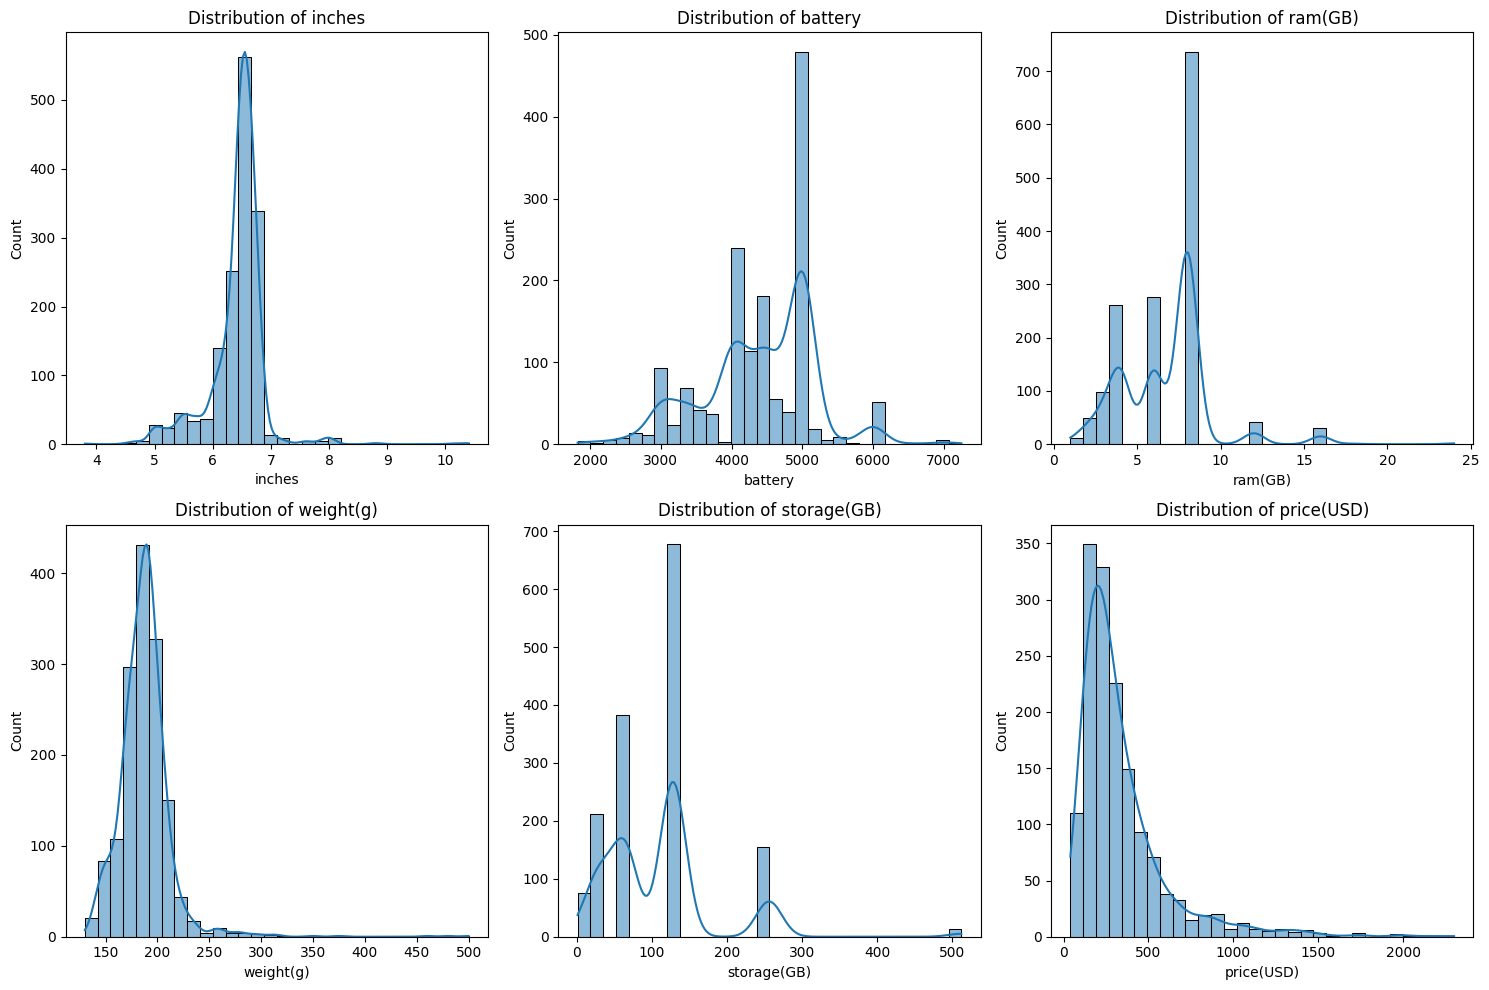

In [5]:
# Biến số
num_cols = ['inches', 'battery', 'ram(GB)', 'weight(g)', 'storage(GB)', 'price(USD)']

plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

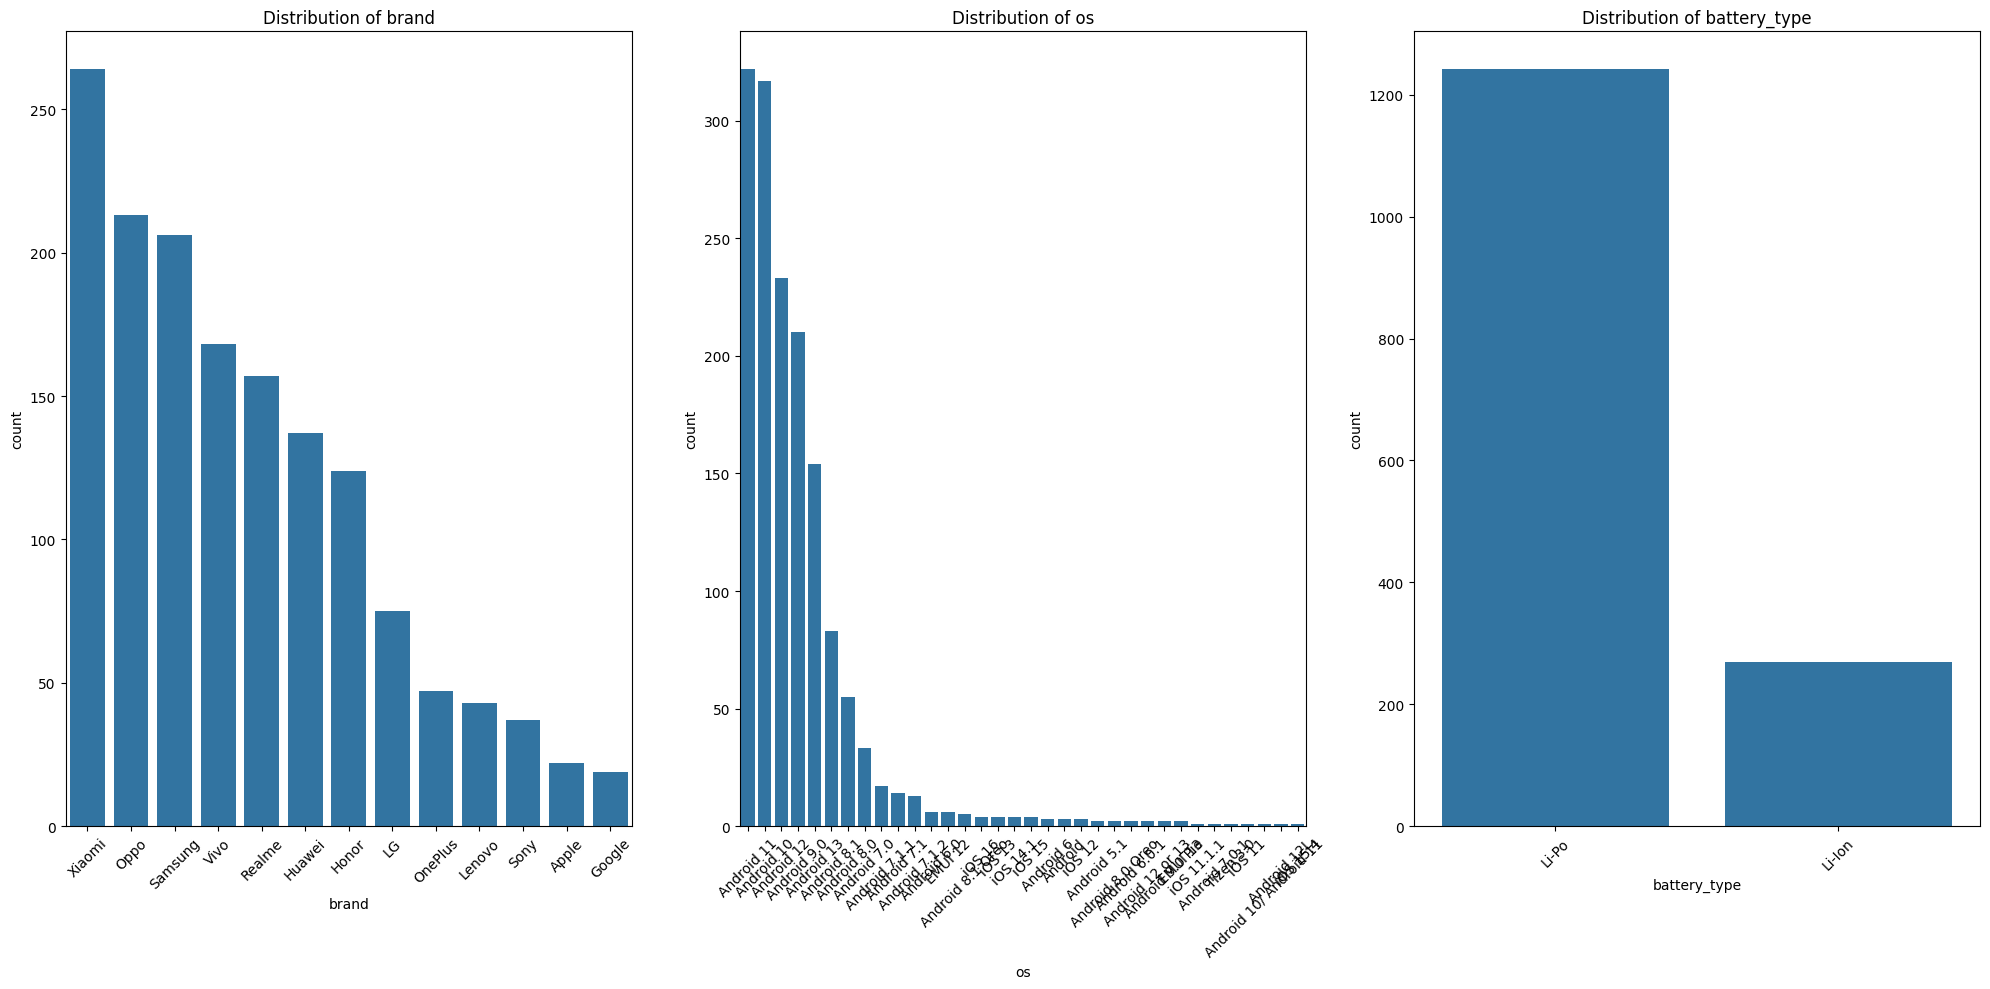

In [6]:
# Biến phân loại
cat_cols = ['brand', 'os', 'battery_type']


plt.figure(figsize=(20,10))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(1, 3, i)
    sns.countplot(x=df[col], order=df[col].value_counts().index)
    plt.xticks(rotation=45)
    plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

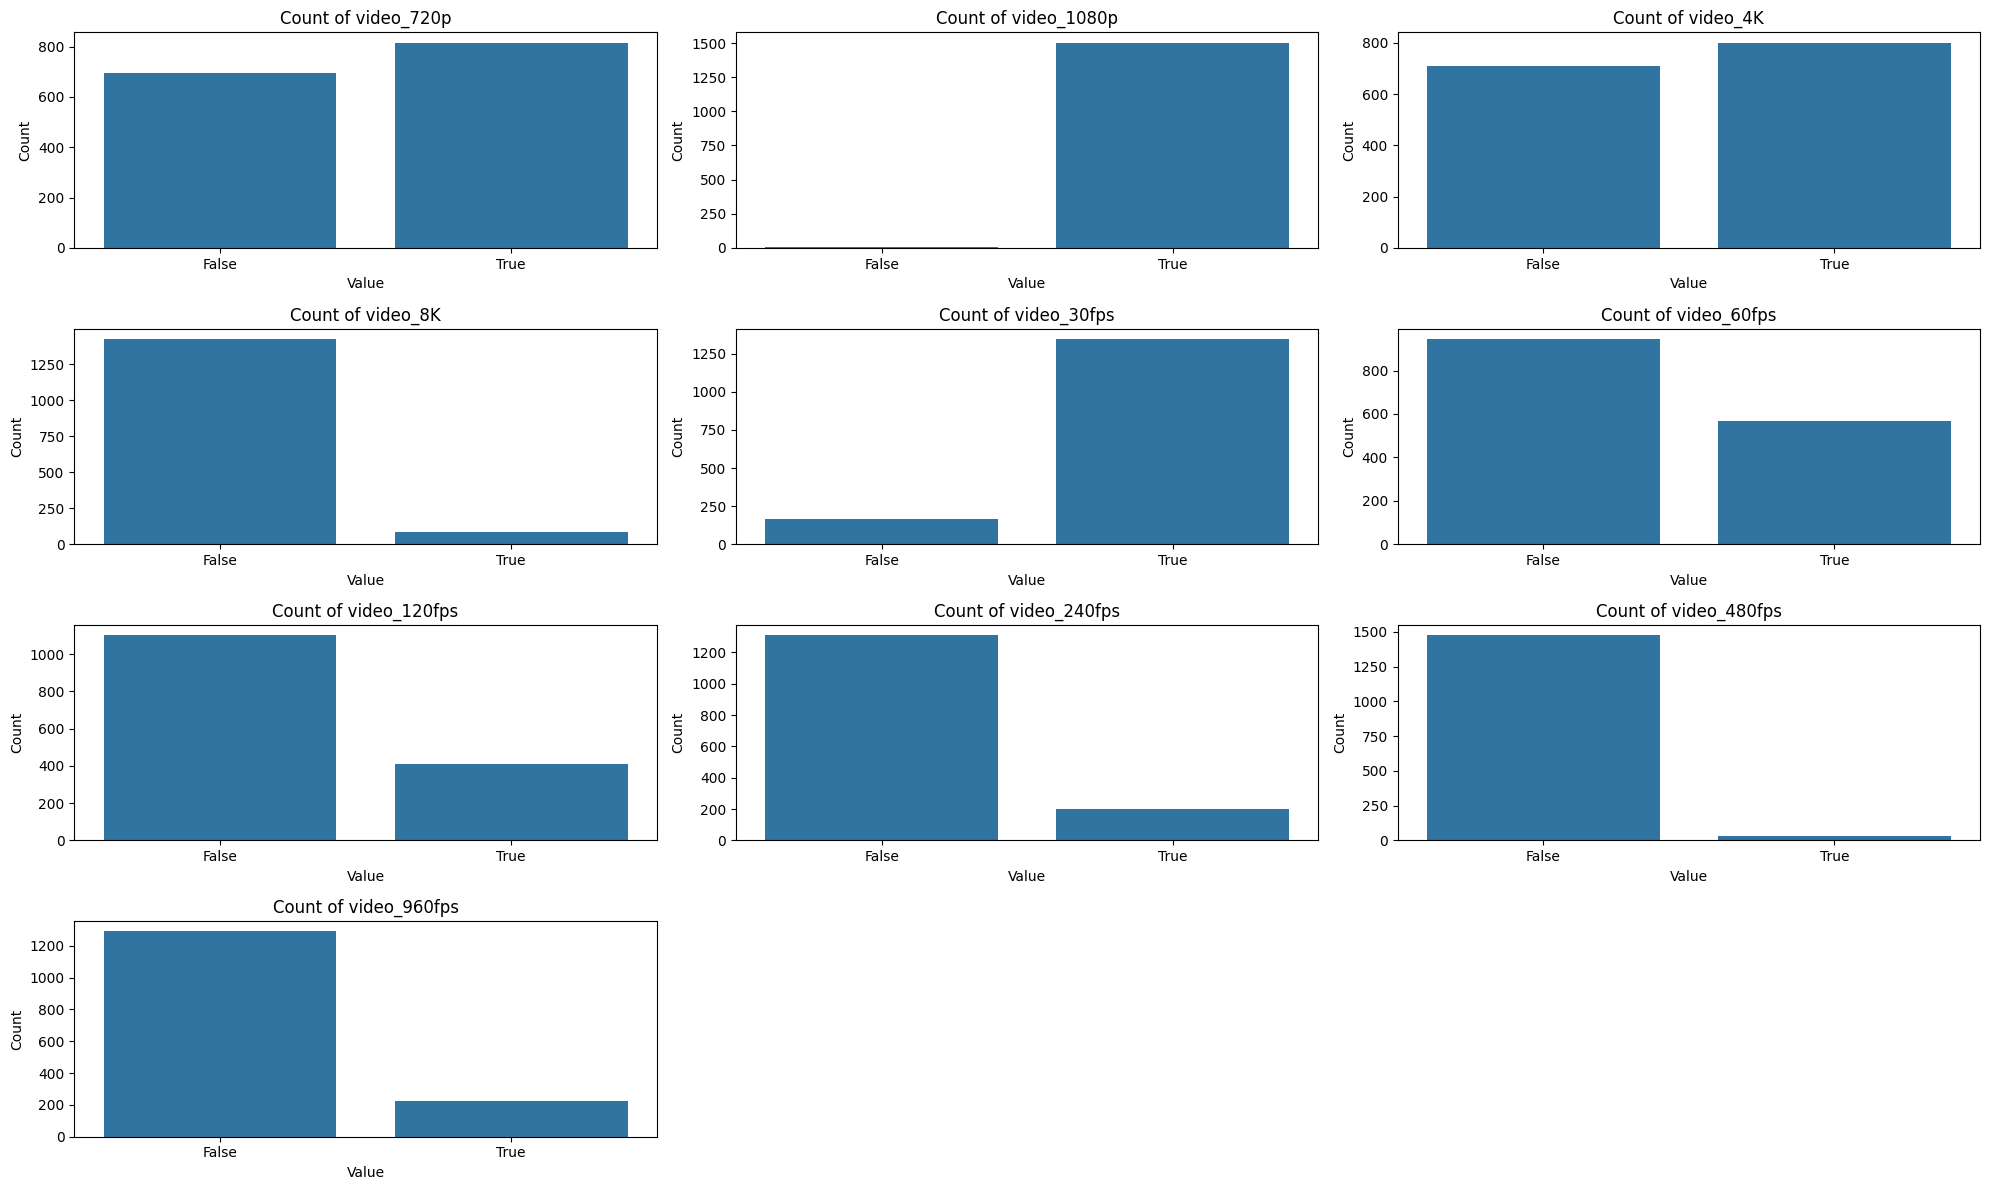

In [7]:
# Biến boolean
boolean_cols = ['video_720p', 'video_1080p', 'video_4K', 'video_8K',
                'video_30fps', 'video_60fps', 'video_120fps',
                'video_240fps', 'video_480fps', 'video_960fps']
# Độ phân giải - tốc độ khung hình khi quay

plt.figure(figsize=(20, 12))
for i, col in enumerate(boolean_cols, 1):
    plt.subplot(4, 3, i)
    sns.countplot(x=df[col])
    plt.title(f"Count of {col}")
    plt.xlabel("Value")
    plt.ylabel("Count")
plt.tight_layout()
plt.show()

#Phân tích outlier



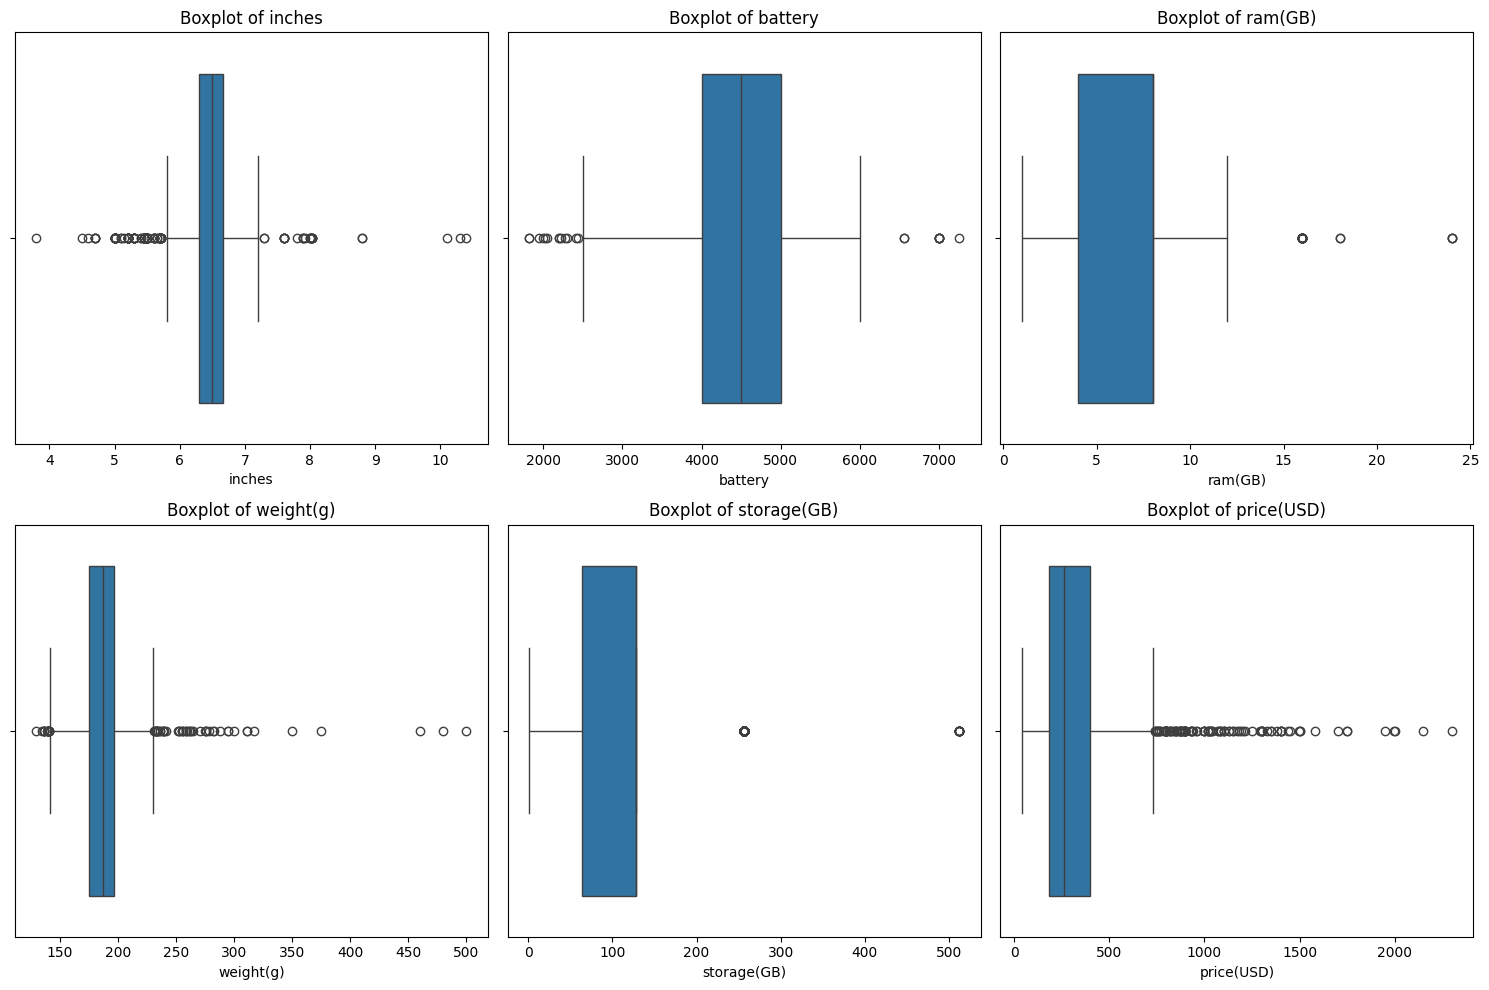

In [8]:
# Vẽ boxplot để kiểm tra outlier biến số
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

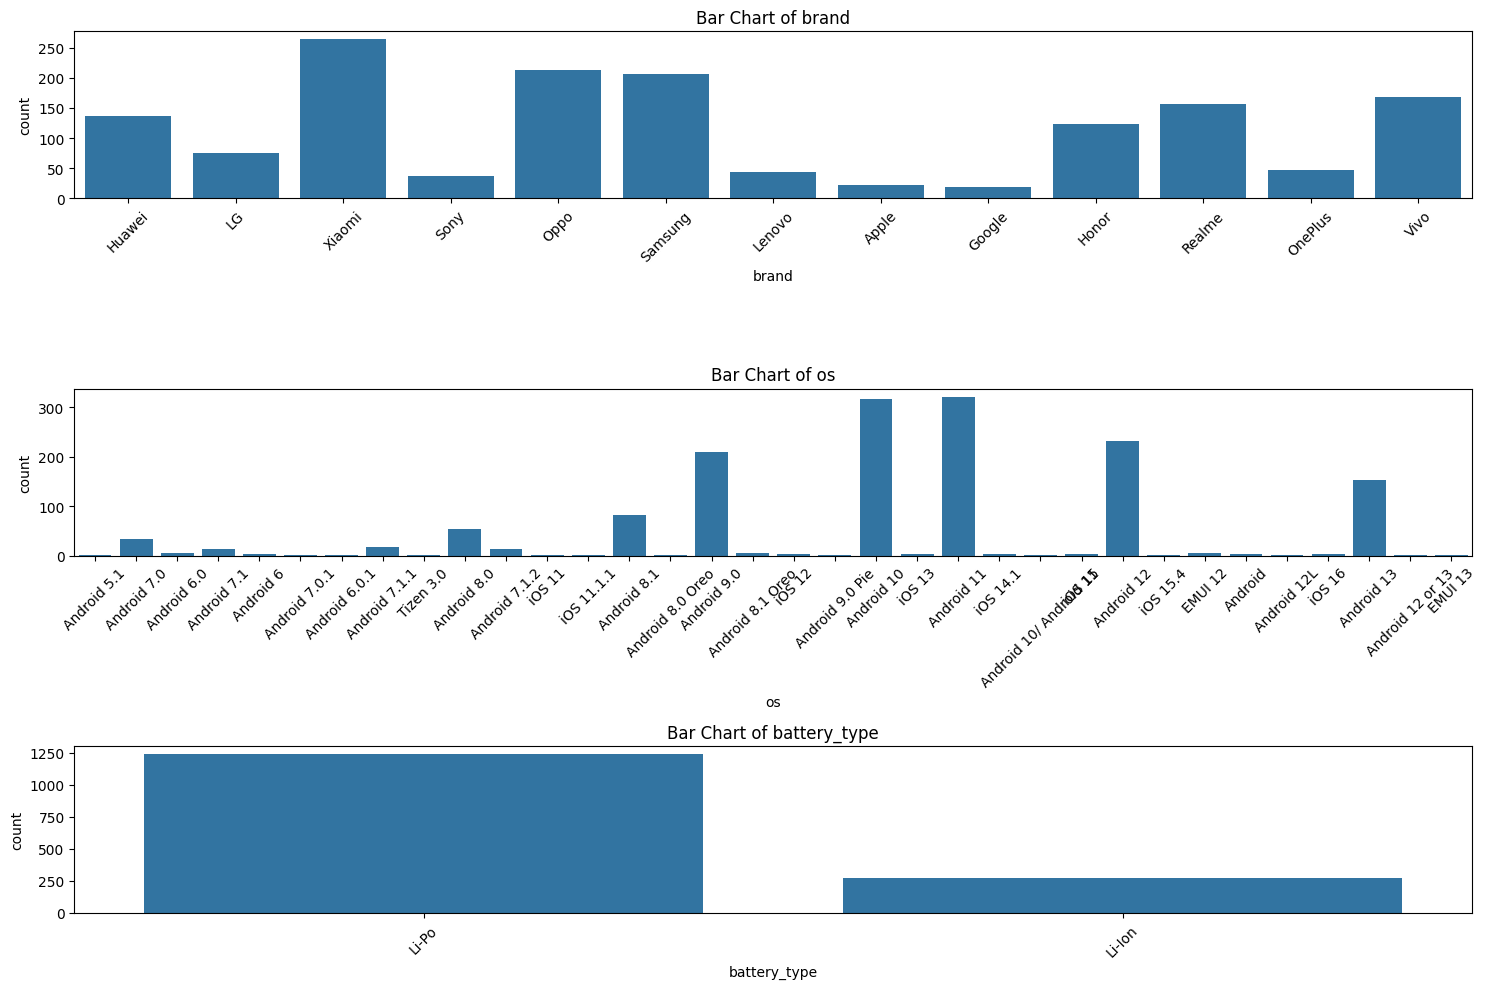

In [9]:
# Vẽ boxplot để kiểm tra outlier biến phân loại
plt.figure(figsize=(15, 10))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 1, i)
    sns.countplot(x=df[col])
    plt.xticks(rotation=45)
    plt.title(f"Bar Chart of {col}")
plt.tight_layout()
plt.show()

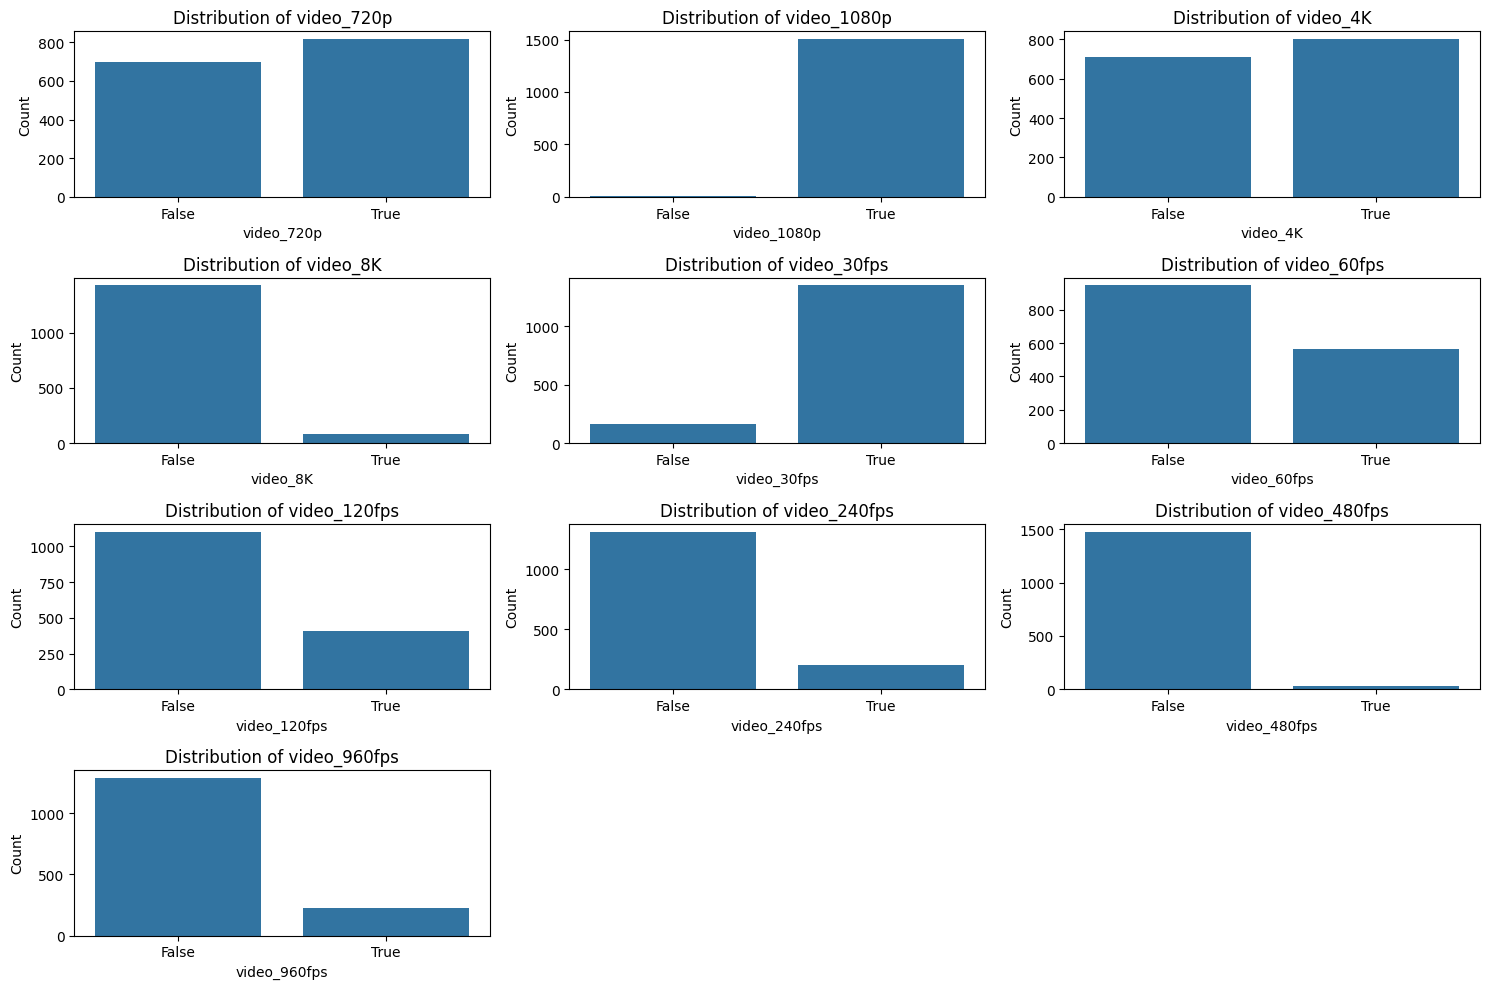

In [21]:
# Vẽ boxplot để kiểm tra outlier biến bool
plt.figure(figsize=(15, 10))
for i, col in enumerate(boolean_cols, 1):
    plt.subplot(4, 3, i)  # Điều chỉnh số hàng và số cột của subplot
    sns.countplot(x=df[col])
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Phân tích đa biến bằng trực quan


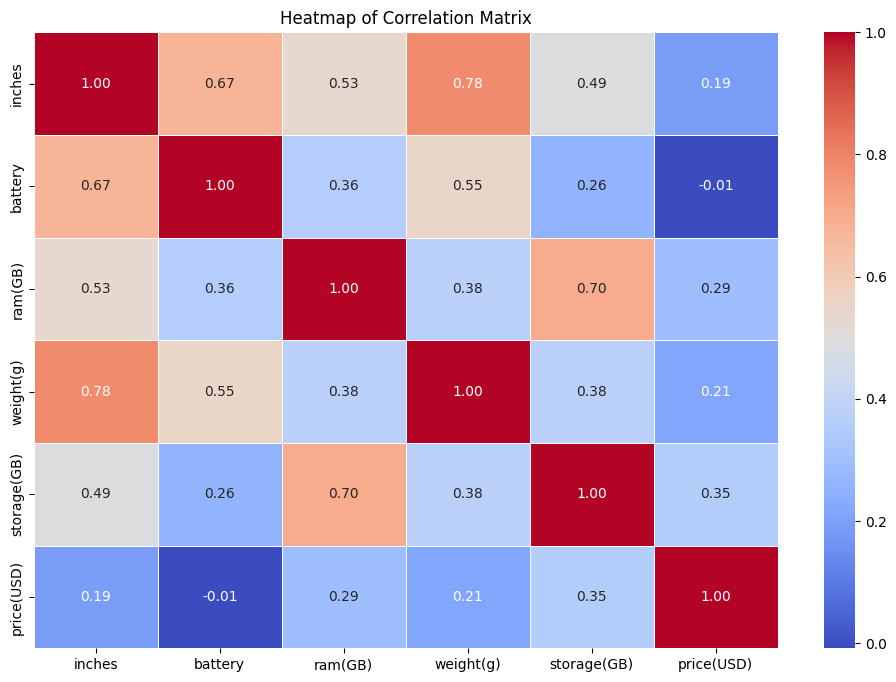

In [11]:
# Trực quan các biến số
corr = df[num_cols].corr()

# Vẽ heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title('Heatmap of Correlation Matrix')
plt.show()

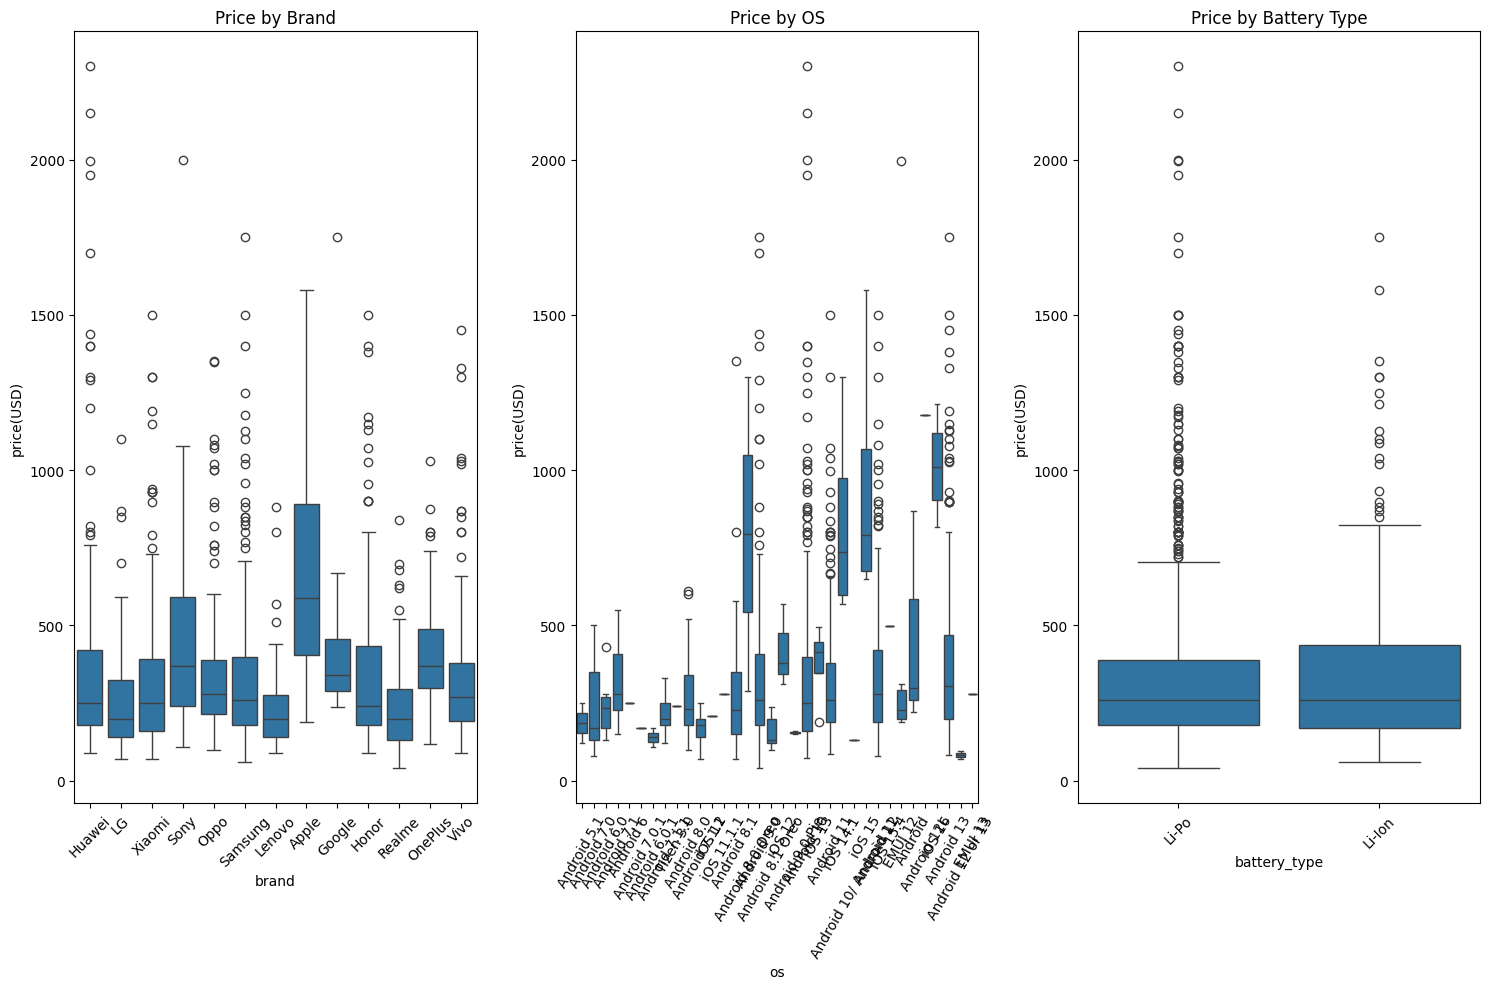

In [12]:
plt.figure(figsize=(15, 10))

# Vẽ boxplot cho 'brand' vs 'price(USD)'
plt.subplot(1, 3, 1)
sns.boxplot(x='brand', y='price(USD)', data=df)
plt.title('Price by Brand')
plt.xticks(rotation=45)

# Vẽ boxplot cho 'os' vs 'price(USD)'
plt.subplot(1, 3, 2)
sns.boxplot(x='os', y='price(USD)', data=df)
plt.title('Price by OS')
plt.xticks(rotation=60)

# Vẽ boxplot cho 'battery_type' vs 'price(USD)'
plt.subplot(1, 3, 3)
sns.boxplot(x='battery_type', y='price(USD)', data=df)
plt.title('Price by Battery Type')
plt.xticks(rotation=45)

# Hiển thị các biểu đồ
plt.tight_layout()
plt.show()

In [13]:
import scipy.stats as stats

# Tính toán ANOVA cho từng biến phân loại so với biến 'price(USD)'
def anova_test(df, category_col, target_col):
    groups = [df[target_col][df[category_col] == category] for category in df[category_col].unique()]
    f_val, p_val = stats.f_oneway(*groups)
    return f_val, p_val

# Kiểm tra ANOVA cho các biến phân loại và biến mục tiêu 'price(USD)'
categories = ['brand', 'os', 'battery_type']

for category in categories:
    f_val, p_val = anova_test(df, category, 'price(USD)')
    print(f"ANOVA test for '{category}' vs 'price(USD)': F-value = {f_val}, p-value = {p_val}")


ANOVA test for 'brand' vs 'price(USD)': F-value = 8.608227625617737, p-value = 5.027898279287666e-16
ANOVA test for 'os' vs 'price(USD)': F-value = 4.2615347602500036, p-value = 2.050735177686309e-14
ANOVA test for 'battery_type' vs 'price(USD)': F-value = 0.44476494895270924, p-value = 0.5049334287307743


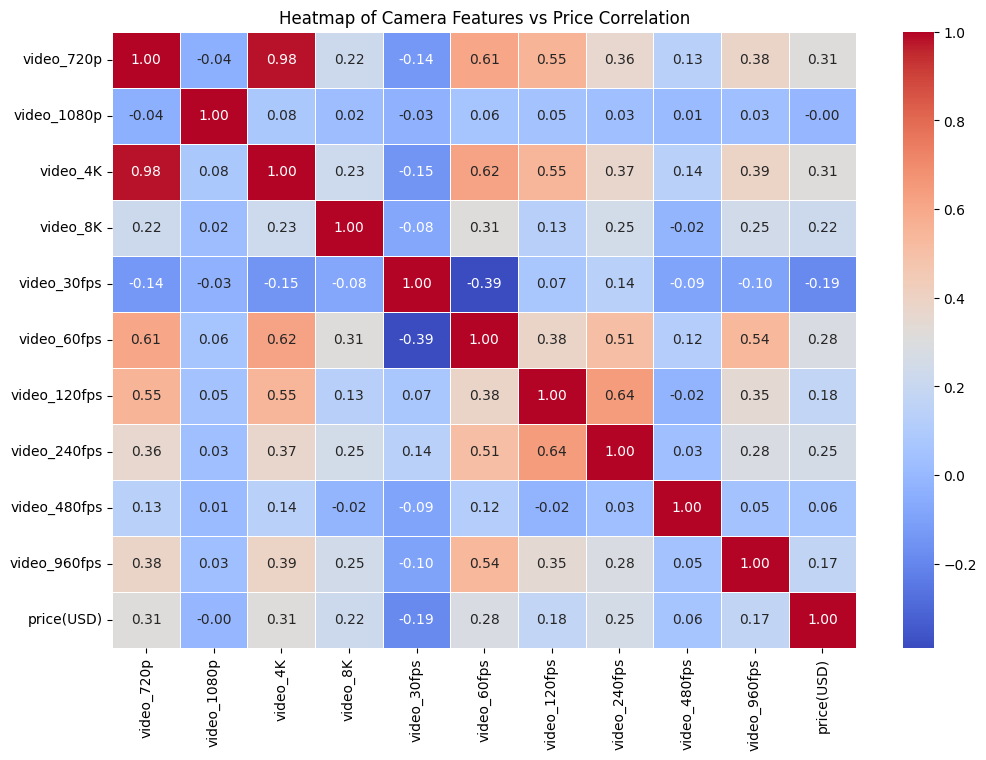

In [14]:
# Lọc các cột cần thiết
camera_cols = ['video_720p', 'video_1080p', 'video_4K', 'video_8K',
                'video_30fps', 'video_60fps', 'video_120fps',
                'video_240fps', 'video_480fps', 'video_960fps', 'price(USD)']

# Tính toán ma trận tương quan
corr = df[camera_cols].corr()

# Vẽ heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title('Heatmap of Camera Features vs Price Correlation')
plt.show()


# Chuyển các cột cấu hình lại thành 1 cột

In [15]:
df.columns

Index(['phone_name', 'brand', 'os', 'inches', 'resolution', 'battery',
       'battery_type', 'ram(GB)', 'announcement_date', 'weight(g)',
       'storage(GB)', 'video_720p', 'video_1080p', 'video_4K', 'video_8K',
       'video_30fps', 'video_60fps', 'video_120fps', 'video_240fps',
       'video_480fps', 'video_960fps', 'price(USD)'],
      dtype='object')

In [16]:
def combine_video_resolutions(row):
    resolutions = []
    if row['video_720p']: resolutions.append('720p')
    if row['video_1080p']: resolutions.append('1080p')
    if row['video_4K']: resolutions.append('4K')
    if row['video_8K']: resolutions.append('8K')
    return ', '.join(resolutions)

# Tạo cột mới
df['video_resolutions'] = df.apply(combine_video_resolutions, axis=1)

In [17]:
def combine_fps(row):
    fps_list = []
    if row['video_30fps']: fps_list.append('30fps')
    if row['video_60fps']: fps_list.append('60fps')
    if row['video_120fps']: fps_list.append('120fps')
    if row['video_240fps']: fps_list.append('240fps')
    if row['video_480fps']: fps_list.append('480fps')
    if row['video_960fps']: fps_list.append('960fps')
    return ', '.join(fps_list) if fps_list else 'None'

df['video_fps'] = df.apply(combine_fps, axis=1)


In [18]:
df.head()

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_8K,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD),video_resolutions,video_fps
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,False,True,False,False,False,False,False,120.0,720p,30fps
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,False,True,False,False,False,False,False,100.0,1080p,30fps
2,P8 Lite (2017),Huawei,Android 7.0,5.2,1080x1920,3000,Li-Ion,4,2017-01-01,147.0,...,False,True,False,False,False,False,False,420.0,1080p,30fps
3,Redmi Note 4,Xiaomi,Android 6.0,5.5,1080x1920,4100,Li-Po,4,2017-01-01,165.0,...,False,True,False,True,False,False,False,150.0,"720p, 1080p","30fps, 120fps"
4,P10,Huawei,Android 7.0,5.1,1080x1920,3200,Li-Ion,4,2017-02-01,145.0,...,False,True,True,False,False,False,False,420.0,"720p, 1080p, 4K","30fps, 60fps"


In [19]:
# Top 10 tổ hợp phổ biến, còn lại gộp vào 'Others'
top_resolutions = df['video_resolutions'].value_counts().nlargest(10).index
df['video_res_group'] = df['video_resolutions'].apply(lambda x: x if x in top_resolutions else 'Others')

top_fps = df['video_fps'].value_counts().nlargest(10).index
df['video_fps_group'] = df['video_fps'].apply(lambda x: x if x in top_fps else 'Others')

In [20]:
from scipy.stats import f_oneway

def anova_test(df, cat_col, target_col):
    groups = [df[target_col][df[cat_col] == g] for g in df[cat_col].unique()]
    return f_oneway(*groups)

# ANOVA giữa độ phân giải video và giá
f_res, p_res = anova_test(df, 'video_res_group', 'price(USD)')
print(f"[video_resolutions] F = {f_res:.2f}, p = {p_res:.4f}")

# ANOVA giữa fps video và giá
f_fps, p_fps = anova_test(df, 'video_fps_group', 'price(USD)')
print(f"[video_fps] F = {f_fps:.2f}, p = {p_fps:.4f}")


[video_resolutions] F = 34.89, p = 0.0000
[video_fps] F = 22.17, p = 0.0000


Nhận xét: Ảnh hưởng cực mạnh tới giá điện thoại